In [64]:
import pandas as pd
from pathlib import Path
import os
from IPython.display import display
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

In [65]:
# Import cvs files

print(os.getcwd())
print(os.listdir("."))

# place all data sources into folder call "data" alongside this .ipynb file
data_location = Path("data")


# Create a dictionary into which we wil aec the four dataframes and align them with the file names, for ease of access
# This will save us time cleaning the dfs individually with any repitive tasks 
data_sources= {}

print(data_location)

for i in sorted(data_location.glob("*.csv")):
    #strip back file name to just prefix, split at every dot and take first item and convert to lower case for consistency
    stripped_dfname= i.stem.split(".")[0].lower()
    # read csv file into a dataframe - red as utf8 and strip the hidden byte orser mark... as gettng corrupt characters..
    df = pd.read_csv(i, header=0, encoding="utf-8-sig")
    # standardise column names
    df.columns =df.columns.str.lower().str.replace(" ", "_")
    # stpre thb dataframe in the dictionary
    data_sources[stripped_dfname] = df
    # have a llok to make sure file names match into dataframe name in the dictionary and check shape to verify df is good
    print(f"{stripped_dfname} : {df.shape} <-{i.name}")


# Call the dictionary key names to show the dataframes present..
data_sources.keys()




e:\GG\Msc\SPEC9995_data_visualisation_marisa llorens-salvador_tues\github\spec9995_data_vis_marissa_tues\assignment 1\working
['working_dea_1.ipynb', 'steps_log.txt', 'data', 'data_overview.txt', 'eda_core_v1.png', 'eda_net_debt_waterfall_v1.png', 'core_features.csv', 'eda_core_v2.png', 'eda_core_v3.png']
data
gfa01 : (899, 5) <-GFA01.20261025T131014.csv
gfa02 : (728, 5) <-GFA02.20261025T141020.csv
gfa03 : (1248, 5) <-GFA03.20261025T141058.csv
gfa04 : (988, 5) <-GFA04.20261025T141047.csv
gfq02 : (1960, 5) <-GFQ02.20261026T041034.csv


dict_keys(['gfa01', 'gfa02', 'gfa03', 'gfa04', 'gfq02'])

In [66]:
# Import .xlsx files

# Find all IFAC xlsx files, skipping Excel's temporary lock files (~$...)
xlsx_files = [f for f in sorted(datalocation.glob("*.xlsx")) if not f.name.startswith("~$")]

# crate dictionary to store them
ifac_xlsx_files={}

# get identifiers for each xls per year i.e. 2023, 2026
for f in xlsx_files:
    # use reg expressin to get first 4 digits as year
    year = re.search(r"20\d{2}", f.name)
    if year:
        ifac_xlsx_files[int(year.group())] = f
        print(f"{year.group()} : {f.name}")

# create nested dictionary with manual location of the data we want to put into dataframe
# manual process to get the data from specific tabs
# w use the tab name, the first number if the the year row, then rows containing the data numbers, use a list value as multiple numbers, include unit text, single digit is multipler to get all value sin same scale i.e. millions or billions, then label valeus as per the tabs themselves, GG stands for general government as per xlsx
ifac2026_tabs_dict={
    "fig2.1": ("Figure 2.1", 33, [34],2, "Euro Million", 1, {34:"GG surplus (incorporating overruns)"}), 
    "fig2.2": ("Figure 2.2", 41, [44],2, "Euro Million", 1, {44:"GG balance (excl excess CT and CJEU)"}), 
    "fig2.9": ("Figure 2.9", 25, [26, 27, 28, 29, 30], 4, "Euro Million", 1, 
               {26: "Contribution - National Training Fund",
                 27: "Contribution - Social Insurance Fund",
                 28: "Contribution - Infrastructure, Climate & Nature Fund",
                 29: "Contribution - Future Ireland Fund",
                 30: "GG surplus (incl. Apple)"}),
    "fig2.10": ("Figure 2.10", 23, [24, 25, 26, 27, 28], 2, "Euro Million", 1000, 
                 {24: "Balance - Social Insurance Fund",
                 25: "Balance - Future Ireland Fund (7.6% return assumed)",
                 26: "Balance - National Training Fund",
                 27: "Balance - Infrastructure, Climate & Nature Fund",
                 28: "Balance - Ireland Strategic Investment Fund"}),
    "fig3.4": ("Figure 3.4", 52, [56, 65],2, "Percent of national income", 1, {56: "CT % national income  -ireland", 65: "CT % of national income Eurpoean avg"}), 
    "fig3.5": ("Figure 3.5", 40, [41],3, "Percent", 1, {41: "% of CT saved (surplus as % of CT)"}), 

    
    
    
}


# Call the dictionary key names to show the dataframes present..

2026 : Data-pack-Fiscal-Assessment-Report-June-2026.xlsx


In [67]:
# take thew IFAC tab data and convert to CSO stye data where years rni fown a column and have the same columsn as CSO

def ifac_block(xl, pack_year, sheet, year_row, rows, first_col, unit, scale, labels, last_actual=2025):
    """Extract chart data (years across a row) into long format matching the CSO schema."""
    raw = pd.read_excel(xl, sheet_name=sheet, header=None)
    years = pd.to_numeric(raw.iloc[year_row - 1, first_col - 1:], errors="coerce")
    out = []
    for r in rows:
        label = labels[r] if labels else str(raw.iloc[r - 1, 0]).strip()
        vals = pd.to_numeric(raw.iloc[r - 1, first_col - 1:], errors="coerce") * scale
        df = pd.DataFrame({"year": years.values, "value": vals.values}).dropna()
        df["year"] = df["year"].astype(int)
        df["item"], df["unit"] = label, unit
        df["source"], df["table"] = "IFAC", f"FAR Jun {pack_year} {sheet}"
        df["is_forecast"] = df["year"] > last_actual
        out.append(df)
    return pd.concat(out, ignore_index=True)[
        ["source", "table", "year", "item", "unit", "value", "is_forecast"]]

In [68]:
# 
xl26 = ifac_xlsx_files[2026]
for name, spec in ifac2026_tabs_dict.items():
    key = f"ifac2026_{name}"
    df = ifac_block(xl26, 2026, *spec)
    data_sources[key] = df
    print(f"{key} : {df.shape} <- {xl26.name} [{spec[0]}]")

# Show the dataframes now held in the dictionary
data_sources.keys()

ifac2026_fig2.1 : (9, 7) <- Data-pack-Fiscal-Assessment-Report-June-2026.xlsx [Figure 2.1]
ifac2026_fig2.2 : (36, 7) <- Data-pack-Fiscal-Assessment-Report-June-2026.xlsx [Figure 2.2]
ifac2026_fig2.9 : (35, 7) <- Data-pack-Fiscal-Assessment-Report-June-2026.xlsx [Figure 2.9]
ifac2026_fig2.10 : (35, 7) <- Data-pack-Fiscal-Assessment-Report-June-2026.xlsx [Figure 2.10]
ifac2026_fig3.4 : (61, 7) <- Data-pack-Fiscal-Assessment-Report-June-2026.xlsx [Figure 3.4]
ifac2026_fig3.5 : (9, 7) <- Data-pack-Fiscal-Assessment-Report-June-2026.xlsx [Figure 3.5]


dict_keys(['gfa01', 'gfa02', 'gfa03', 'gfa04', 'gfq02', 'ifac2026_fig2.1', 'ifac2026_fig2.2', 'ifac2026_fig2.9', 'ifac2026_fig2.10', 'ifac2026_fig3.4', 'ifac2026_fig3.5'])

In [47]:
with open("data_overview.txt", "w", encoding="utf-8") as out:
    for name, df in data_sources.items():
        out.write(f"\n===== {name.upper()} {df.shape} =====\n")
        out.write(f"columns: {df.columns.tolist()}\n\n")
        out.write(df.head(5).to_string() + "\n\n")
        out.write(f"years: {df['year'].min()} -> {df['year'].max()}\n")
        out.write(f"units: {df['unit'].unique().tolist()}\n")
        out.write(f"unique items ({df['item'].nunique()}):\n")
        for item in df["item"].unique():
            out.write(f"    {item}\n")

print("written to data_overview.txt")

KeyError: 'year'

In [ ]:
# print clumn names and first 5 lines of each dataframe
for name, df in data_sources.items():
    print(f" \n ===== {name.lower()} {df.shape} =============")
    print(df.columns.tolist())
    display(df.head(-5))

 
 ===== gfa01 (899, 5) =============
['statistic_label', 'year', 'item', 'unit', 'value']


,statistic_label,year,item,unit,value
0,General Government Transactions ESA 2010: Reve...,1995,General Government transactions - Revenue - ES...,Euro Million,20959
1,General Government Transactions ESA 2010: Reve...,1995,General Government transactions - Revenue - Ta...,Euro Million,18262
2,General Government Transactions ESA 2010: Reve...,1995,General Government transactions - Revenue - Ta...,Euro Million,14933
3,General Government Transactions ESA 2010: Reve...,1995,General Government transactions - Revenue - So...,Euro Million,3329
4,General Government Transactions ESA 2010: Reve...,1995,General Government transactions - Revenue - Sa...,Euro Million,982


 
 ===== gfa02 (728, 5) =============
['statistic_label', 'year', 'item', 'unit', 'value']


,statistic_label,year,item,unit,value
0,"General Government Net Worth, Gross and Net De...",2000,General Government net worth - Net Worth at ma...,Euro Million,43644
1,"General Government Net Worth, Gross and Net De...",2000,General Government net worth - Non-financial a...,Euro Million,58293
2,"General Government Net Worth, Gross and Net De...",2000,General Government net worth - Financial net w...,Euro Million,-14650
3,"General Government Net Worth, Gross and Net De...",2000,"Financial net worth at market value, excluding...",Euro Million,27384
4,"General Government Net Worth, Gross and Net De...",2000,"Financial net worth at market value, excluding...",Euro Million,12858


 
 ===== gfa03 (1248, 5) =============
['statistic_label', 'year', 'item', 'unit', 'value']


,statistic_label,year,item,unit,value
0,General Government: Detailed classification of...,2000,Revenue - Total Revenue - ESA2010 Code (TR),Euro Million,38432.0
1,General Government: Detailed classification of...,2000,Revenue - Taxes and social contributions - ESA...,Euro Million,34508.0
2,General Government: Detailed classification of...,2000,Revenue - Total Taxes - ESA2010 Code (D2 + D5 ...,Euro Million,29176.0
3,General Government: Detailed classification of...,2000,Revenue - Indirect taxes (taxes on production ...,Euro Million,14040.0
4,General Government: Detailed classification of...,2000,Revenue - Taxes on products - ESA2010 Code (D21),Euro Million,13195.0


 
 ===== gfa04 (988, 5) =============
['statistic_label', 'year', 'item', 'unit', 'value']


,statistic_label,year,item,unit,value
0,General Government: Detailed classification of...,2000,Expenditure - Total Expenditure - ESA2010 Code...,Euro Million,33165
1,General Government: Detailed classification of...,2000,Expenditure - Expense - ESA2010 Code (Expense),Euro Million,31209
2,General Government: Detailed classification of...,2000,Expenditure - Compensation of employees - ESA2...,Euro Million,8917
3,General Government: Detailed classification of...,2000,Expenditure - Compensation of employees Relate...,Euro Million,0
4,General Government: Detailed classification of...,2000,Expenditure - Use of goods and services plus t...,Euro Million,5492


In [38]:
gfa01, gfa02, gfa03, gfa04 = (data_sources[k] for k in ["gfa01", "gfa02", "gfa03", "gfa04"])

# 1. Where are GFA03's NaNs?
na = gfa03[gfa03["value"].isna()]
print(na.groupby("item")["year"].apply(list))

# 2. Pull a series by ESA code (matches the code in brackets)
def series(df, pattern):
    s = df[df["item"].str.contains(pattern, regex=False)]
    return s.set_index("year")["value"]

# 3. Cross-table consistency checks
check = pd.DataFrame({
    "TR_gfa01": series(gfa01, "Revenue - ESA2010 Code (TR)"),
    "TR_gfa03": series(gfa03, "Total Revenue - ESA2010 Code (TR)"),
    "TE_gfa01": series(gfa01, "Expenditure - ESA2010 Code (TE)"),
    "TE_gfa04": series(gfa04, "Total Expenditure - ESA2010 Code (TE)"),
}).loc[2000:]
check["TR_diff"] = check["TR_gfa01"] - check["TR_gfa03"]
check["TE_diff"] = check["TE_gfa01"] - check["TE_gfa04"]
print(check[["TR_diff", "TE_diff"]].abs().max())   # hope for 0

# 4. First look at the core story
core = pd.DataFrame({
    "corp_tax":    series(gfa03, "Corporation tax"),
    "total_taxes": series(gfa03, "Total Taxes"),
    "surplus":     series(gfa01, "(B9)"),
    "gross_debt":  series(gfa02, "Gross General Government Debt - ESA2010 Code (GGDebt)"),
    "net_debt":    series(gfa02, "(GGNetDebt)"),
}).loc[2000:]
core["ct_share_of_taxes_%"] = (core["corp_tax"] / core["total_taxes"] * 100).round(1)
print(core)

item
Output - Compensation of employees of market establishments - ESA2010 Code (D1_market)                                 [2000, 2001, 2002, 2003, 2004, 2005, 2006, 200...
Output - Consumption of fixed capital related to production of own-use capital assets - ESA2010 Code (P51c_own_use)    [2000, 2001, 2002, 2003, 2004, 2005, 2006, 200...
Output - Intermediate consumption related to production of own-use capital assets - ESA2010 Code (P2_own-use)          [2000, 2001, 2002, 2003, 2004, 2005, 2006, 200...
Name: year, dtype: object
TR_diff    1.0
TE_diff    0.0
dtype: float64
      corp_tax  total_taxes  surplus  gross_debt  net_debt  \
year                                                         
2000    3885.0      29176.0     5268     39506.0   26648.0   
2001    4144.0      30213.0     1171     40995.0   25481.0   
2002    4804.0      32730.0     -706     42009.0   30843.0   
2003    5155.0      36009.0      504     43429.0   32105.0   
2004    5335.0      40060.0     2029     4391

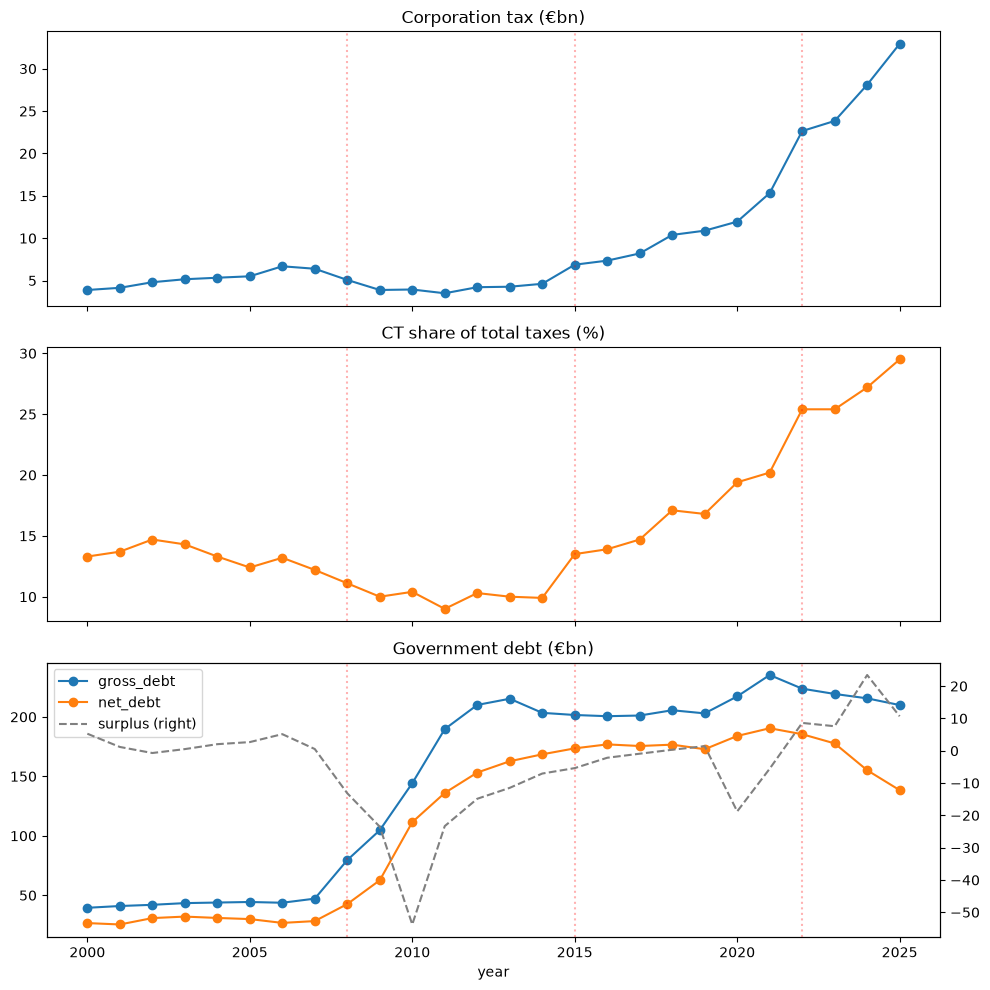

In [39]:
import matplotlib.pyplot as plt

fig, axes = plt.subplots(3, 1, figsize=(10, 10), sharex=True)

core["corp_tax"].div(1000).plot(ax=axes[0], marker="o", title="Corporation tax (€bn)")
core["ct_share_of_taxes_%"].plot(ax=axes[1], marker="o", color="tab:orange", title="CT share of total taxes (%)")
core[["gross_debt", "net_debt"]].div(1000).plot(ax=axes[2], marker="o", title="Government debt (€bn)")
core["surplus"].div(1000).plot(ax=axes[2], secondary_y=True, style="--", color="grey", legend=True)

for ax in axes:
    for yr in (2008, 2015, 2022):
        ax.axvline(yr, color="red", alpha=0.3, linestyle=":")
plt.tight_layout()
plt.savefig("eda_core_v1.png", dpi=120)   # save as iterations evidence
plt.show()

In [40]:
# whats driving the drop in debt i.e. Net debt - aying off the debt, savings/investments, company opr prvate individual savings?

d = core[["gross_debt", "net_debt"]].copy()
d["govt_debt_assets"] = d["gross_debt"] - d["net_debt"]
decomp = d.diff().loc[2022:]
decomp.columns = ["Δ gross debt", "Δ net debt", "Δ govt cash/bond assets"]
decomp["GFA01 check (F2+F3+F4 assets)"] = series(gfa01, "Net acquisition of financial assets - Debt instruments").loc[2022:]
print(decomp.round(0))

      Δ gross debt  Δ net debt  Δ govt cash/bond assets  \
year                                                      
2022      -11486.0     -5022.0                  -6464.0   
2023       -4435.0     -7741.0                   3306.0   
2024       -3690.0    -22545.0                  18855.0   
2025       -5648.0    -16764.0                  11116.0   

      GFA01 check (F2+F3+F4 assets)  
year                                 
2022                          -6509  
2023                           3176  
2024                          18354  
2025                          11358  


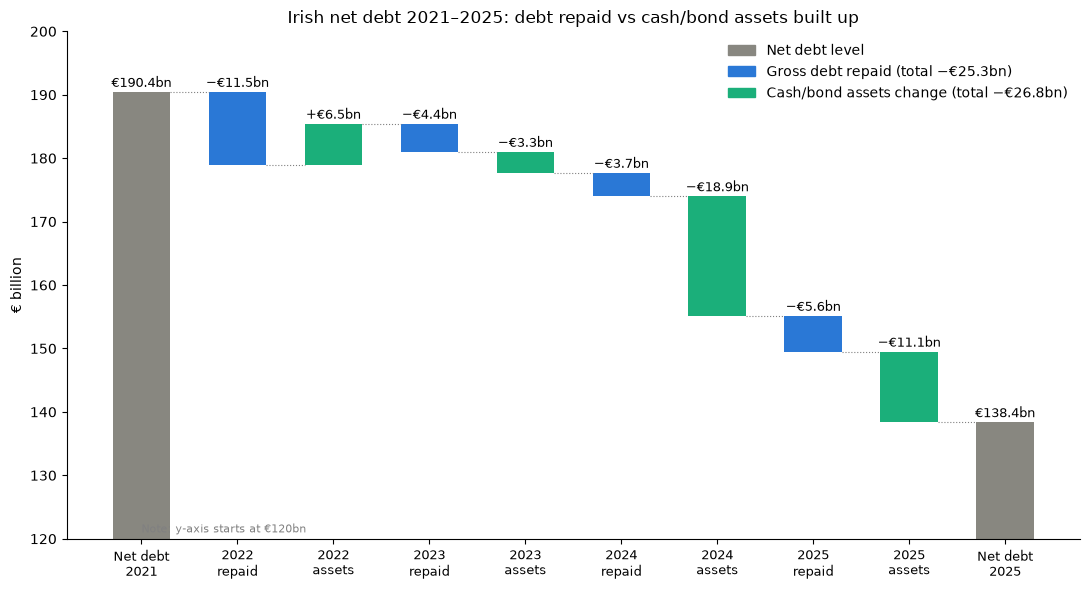

In [41]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

# --- Build the steps from the data (values in €bn) ---
d = core[["gross_debt", "net_debt"]].loc[2021:2025].div(1000)
d["assets"] = d["gross_debt"] - d["net_debt"]
chg = d.diff().loc[2022:]

steps = [("Net debt\n2021", d.loc[2021, "net_debt"], "total")]
for yr, row in chg.iterrows():
    steps.append((f"{yr}\nrepaid", row["gross_debt"], "gross"))   # negative = debt repaid
    steps.append((f"{yr}\nassets", -row["assets"], "assets"))     # more assets -> lower net debt
steps.append(("Net debt\n2025", d.loc[2025, "net_debt"], "total"))

colours = {"total": "#888780", "gross": "#2a78d6", "assets": "#1baf7a"}

# --- Plot ---
fig, ax = plt.subplots(figsize=(11, 6))
running = 0
for i, (label, val, kind) in enumerate(steps):
    if kind == "total":
        bottom, height = 0, val
        running = val
        text = f"€{val:.1f}bn"
    else:
        bottom = running if val >= 0 else running + val
        height = abs(val)
        running += val
        text = f"{'+' if val >= 0 else '−'}€{abs(val):.1f}bn"
    ax.bar(i, height, bottom=bottom, color=colours[kind], width=0.6)
    ax.text(i, bottom + height + 0.8, text, ha="center", fontsize=9)

    # connector line to next bar
    if i < len(steps) - 1:
        ax.plot([i + 0.3, i + 0.7], [running, running], color="grey", lw=0.8, ls=":")

ax.set_xticks(range(len(steps)))
ax.set_xticklabels([s[0] for s in steps], fontsize=9)
ax.set_ylim(120, 200)                       # truncated axis: label it in the report
ax.set_ylabel("€ billion")
ax.set_title("Irish net debt 2021–2025: debt repaid vs cash/bond assets built up")
ax.spines[["top", "right"]].set_visible(False)

ax.legend(handles=[
    mpatches.Patch(color=colours["total"], label="Net debt level"),
    mpatches.Patch(color=colours["gross"], label=f"Gross debt repaid (total −€{-chg['gross_debt'].sum():.1f}bn)"),
    mpatches.Patch(color=colours["assets"], label=f"Cash/bond assets change (total −€{chg['assets'].sum():.1f}bn)"),
], loc="upper right", frameon=False)

ax.text(0, 121, "Note: y-axis starts at €120bn", fontsize=8, color="grey")
plt.tight_layout()
plt.savefig("eda_net_debt_waterfall_v1.png", dpi=120)
plt.show()

Normal CT share 2000-2014: 11.86%
      corp_tax  ct_normal  ct_excess  ifac_central
year                                              
2014      4.62       5.52       0.00          0.00
2015      6.87       6.03       0.84          1.65
2016      7.35       6.28       1.07          1.12
2017      8.20       6.63       1.57          1.51
2018     10.39       7.20       3.18          3.10
2019     10.89       7.69       3.19          3.02
2020     11.95       7.32       4.63          4.67
2021     15.32       9.01       6.31          6.54
2022     22.64      10.57      12.07         11.46
2023     23.84      11.13      12.71           NaN
2024     28.11      12.26      15.85           NaN
2025     32.94      13.26      19.68           NaN


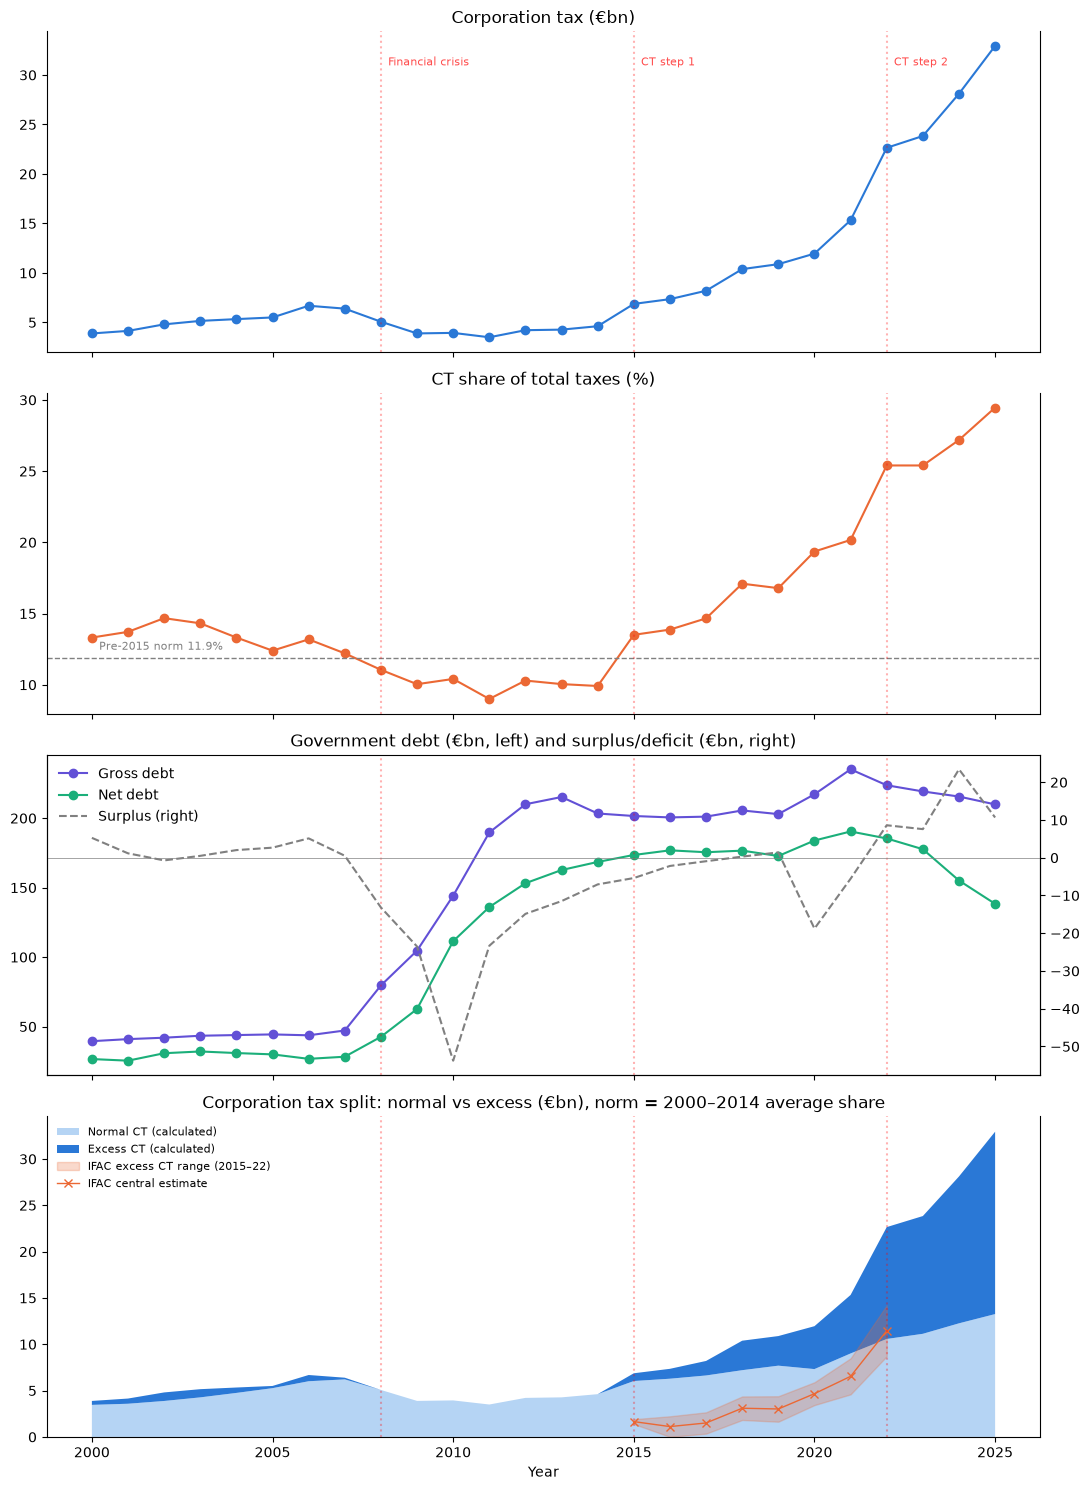

In [42]:
import matplotlib.pyplot as plt
from pathlib import Path

# ---------- 1. Calculated features ----------
NORM_START, NORM_END = 2000, 2014

core["ct_share_of_taxes_%"] = core["corp_tax"] / core["total_taxes"] * 100
norm = (core["corp_tax"] / core["total_taxes"]).loc[NORM_START:NORM_END].mean()

core["ct_normal"] = norm * core["total_taxes"]
core["ct_excess"] = (core["corp_tax"] - core["ct_normal"]).clip(lower=0)
core["ct_normal_plot"] = core["corp_tax"] - core["ct_excess"]   # normal part, capped at actual CT
core["ct_excess_share_%"] = core["ct_excess"] / core["corp_tax"] * 100
core["surplus_excl_excess"] = core["surplus"] - core["ct_excess"]
core["norm_share_%"] = norm * 100
core["norm_period"] = f"{NORM_START}-{NORM_END}"

# ---------- 2. IFAC estimates for validation (June 2023 data pack, Figure D2) ----------
xl = Path("data") / "Data-Pack-June-2023-FAR.xlsx"     # adjust if your filename differs
d2 = pd.read_excel(xl, sheet_name="Figure D2", header=None,
                   skiprows=30, nrows=13, usecols="B:D,F")
d2.columns = ["ifac_low", "ifac_central", "ifac_high", "dof_estimate"]
d2.insert(0, "year", range(2014, 2027))
ifac = d2.set_index("year").loc[:2022] * 1000           # € bn -> € m, actual years only

core = core.join(ifac[["ifac_low", "ifac_central", "ifac_high"]], how="left")

# ---------- 3. Save ----------
core.round(2).to_csv("core_features.csv", index_label="year")
print(f"Normal CT share {NORM_START}-{NORM_END}: {norm:.2%}")
print(core.loc[2014:, ["corp_tax", "ct_normal", "ct_excess", "ifac_central"]].div(1000).round(2))

# ---------- 4. Plot ----------
events = {2008: "Financial crisis", 2015: "CT step 1", 2022: "CT step 2"}
bn = lambda s: s / 1000

fig, axes = plt.subplots(4, 1, figsize=(11, 15), sharex=True)

# Panel 1: CT
ax = axes[0]
ax.plot(core.index, bn(core["corp_tax"]), marker="o", color="#2a78d6")
ax.set_title("Corporation tax (€bn)")

# Panel 2: CT share of taxes
ax = axes[1]
ax.plot(core.index, core["ct_share_of_taxes_%"], marker="o", color="#eb6834")
ax.axhline(norm * 100, color="grey", ls="--", lw=1)
ax.text(2000.2, norm * 100 + 0.6, f"Pre-2015 norm {norm:.1%}", fontsize=8, color="grey")
ax.set_title("CT share of total taxes (%)")

# Panel 3: debt and surplus
ax = axes[2]
ax.plot(core.index, bn(core["gross_debt"]), marker="o", color="#6250d6", label="Gross debt")
ax.plot(core.index, bn(core["net_debt"]), marker="o", color="#1baf7a", label="Net debt")
ax2 = ax.twinx()
ax2.plot(core.index, bn(core["surplus"]), ls="--", color="grey", label="Surplus (right)")
ax2.axhline(0, color="grey", lw=0.5)
ax.set_title("Government debt (€bn, left) and surplus/deficit (€bn, right)")
lines = ax.get_legend_handles_labels(); lines2 = ax2.get_legend_handles_labels()
ax.legend(lines[0] + lines2[0], lines[1] + lines2[1], loc="upper left", frameon=False)

# Panel 4: normal vs excess CT, with IFAC range for validation
ax = axes[3]
ax.stackplot(core.index, bn(core["ct_normal_plot"]), bn(core["ct_excess"]),
             colors=["#b5d4f4", "#2a78d6"], labels=["Normal CT (calculated)", "Excess CT (calculated)"])
v = core.loc[2015:2022]
ax.fill_between(v.index, bn(v["ifac_low"]), bn(v["ifac_high"]),
                color="#eb6834", alpha=0.25, label="IFAC excess CT range (2015–22)")
ax.plot(v.index, bn(v["ifac_central"]), color="#eb6834", marker="x", lw=1, label="IFAC central estimate")
ax.set_title(f"Corporation tax split: normal vs excess (€bn), norm = {NORM_START}–{NORM_END} average share")
ax.legend(loc="upper left", frameon=False, fontsize=8)

# Shared annotations
for ax in axes:
    for yr, lab in events.items():
        ax.axvline(yr, color="red", alpha=0.3, ls=":")
    ax.spines[["top"]].set_visible(False)
for yr, lab in events.items():
    axes[0].text(yr + 0.2, axes[0].get_ylim()[1] * 0.9, lab, fontsize=8, color="red", alpha=0.7)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.savefig("eda_core_v2.png", dpi=120)
plt.show()

Normal CT share 2000-2014: 11.86%
      corp_tax  ct_normal  ct_excess_signed  ct_excess  ifac_central
year                                                                
2000      3.88       3.46              0.42       0.42           NaN
2001      4.14       3.58              0.56       0.56           NaN
2002      4.80       3.88              0.92       0.92           NaN
2003      5.16       4.27              0.88       0.88           NaN
2004      5.34       4.75              0.58       0.58           NaN
2005      5.50       5.27              0.24       0.24           NaN
2006      6.68       6.01              0.67       0.67           NaN
2007      6.39       6.21              0.18       0.18           NaN
2008      5.07       5.44             -0.37       0.00           NaN
2009      3.89       4.59             -0.70       0.00           NaN
2010      3.94       4.49             -0.55       0.00           NaN
2011      3.50       4.61             -1.11       0.00           NaN


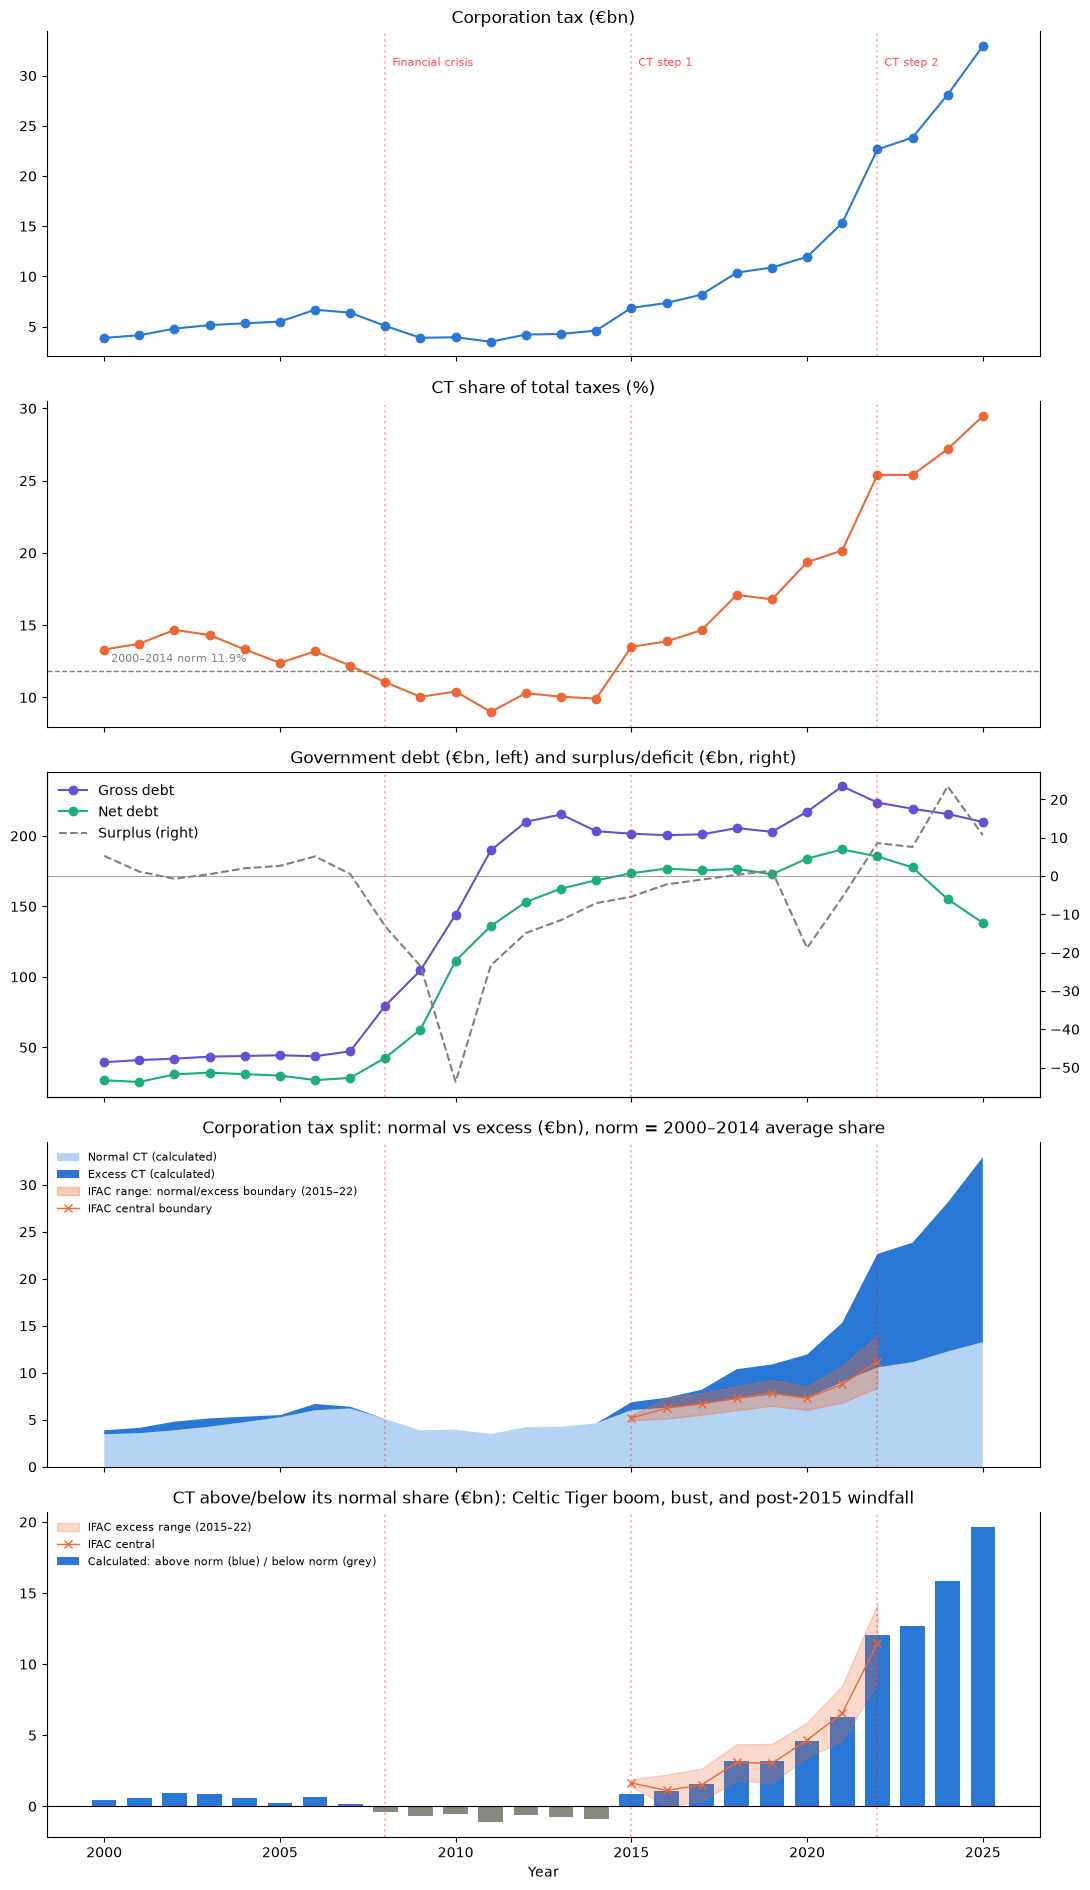

In [43]:

# ---------- 1. Calculated features ----------
NORM_START, NORM_END = 2000, 2014

core["ct_share_of_taxes_%"] = core["corp_tax"] / core["total_taxes"] * 100
norm = (core["corp_tax"] / core["total_taxes"]).loc[NORM_START:NORM_END].mean()

core["ct_normal"] = norm * core["total_taxes"]
core["ct_excess_signed"] = core["corp_tax"] - core["ct_normal"]          # +ve above norm, -ve below
core["ct_excess"] = core["ct_excess_signed"].clip(lower=0)               # windfall only (>= 0)
core["ct_normal_plot"] = core["corp_tax"] - core["ct_excess"]            # normal part, capped at actual CT
core["ct_excess_share_%"] = core["ct_excess"] / core["corp_tax"] * 100
core["surplus_excl_excess"] = core["surplus"] - core["ct_excess"]       # remove windfall only
core["norm_share_%"] = norm * 100
core["norm_period"] = f"{NORM_START}-{NORM_END}"

# ---------- 2. IFAC estimates for validation (June 2023 data pack, Figure D2) ----------
xl = Path("data") / "Data-Pack-June-2023-FAR.xlsx"     # adjust if your filename differs
d2 = pd.read_excel(xl, sheet_name="Figure D2", header=None,
                   skiprows=30, nrows=13, usecols="B:D,F")
d2.columns = ["ifac_low", "ifac_central", "ifac_high", "dof_estimate"]
d2.insert(0, "year", range(2014, 2027))
ifac = d2.set_index("year").loc[:2022] * 1000           # € bn -> € m, actual years only

core = core.drop(columns=["ifac_low", "ifac_central", "ifac_high"], errors="ignore")  # safe re-run
core = core.join(ifac[["ifac_low", "ifac_central", "ifac_high"]], how="left")

# ---------- 3. Save ----------
core.round(2).to_csv("core_features.csv", index_label="year")
print(f"Normal CT share {NORM_START}-{NORM_END}: {norm:.2%}")
print(core[["corp_tax", "ct_normal", "ct_excess_signed", "ct_excess", "ifac_central"]].div(1000).round(2))

# ---------- 4. Plot ----------
events = {2008: "Financial crisis", 2015: "CT step 1", 2022: "CT step 2"}
bn = lambda s: s / 1000

fig, axes = plt.subplots(5, 1, figsize=(11, 19), sharex=True)

# Panel 1: CT
ax = axes[0]
ax.plot(core.index, bn(core["corp_tax"]), marker="o", color="#2a78d6")
ax.set_title("Corporation tax (€bn)")

# Panel 2: CT share of taxes
ax = axes[1]
ax.plot(core.index, core["ct_share_of_taxes_%"], marker="o", color="#eb6834")
ax.axhline(norm * 100, color="grey", ls="--", lw=1)
ax.text(2000.2, norm * 100 + 0.6, f"{NORM_START}–{NORM_END} norm {norm:.1%}", fontsize=8, color="grey")
ax.set_title("CT share of total taxes (%)")

# Panel 3: debt and surplus
ax = axes[2]
ax.plot(core.index, bn(core["gross_debt"]), marker="o", color="#6250d6", label="Gross debt")
ax.plot(core.index, bn(core["net_debt"]), marker="o", color="#1baf7a", label="Net debt")
ax2 = ax.twinx()
ax2.plot(core.index, bn(core["surplus"]), ls="--", color="grey", label="Surplus (right)")
ax2.axhline(0, color="grey", lw=0.5)
ax.set_title("Government debt (€bn, left) and surplus/deficit (€bn, right)")
h1, l1 = ax.get_legend_handles_labels(); h2, l2 = ax2.get_legend_handles_labels()
ax.legend(h1 + h2, l1 + l2, loc="upper left", frameon=False)

# Panel 4: normal vs excess CT, IFAC-implied boundary for validation
ax = axes[3]
ax.stackplot(core.index, bn(core["ct_normal_plot"]), bn(core["ct_excess"]),
             colors=["#b5d4f4", "#2a78d6"],
             labels=["Normal CT (calculated)", "Excess CT (calculated)"])
v = core.loc[2015:2022]
ax.fill_between(v.index, bn(v["corp_tax"] - v["ifac_high"]), bn(v["corp_tax"] - v["ifac_low"]),
                color="#eb6834", alpha=0.35, label="IFAC range: normal/excess boundary (2015–22)")
ax.plot(v.index, bn(v["corp_tax"] - v["ifac_central"]), color="#eb6834", marker="x", lw=1,
        label="IFAC central boundary")
ax.set_title(f"Corporation tax split: normal vs excess (€bn), norm = {NORM_START}–{NORM_END} average share")
ax.legend(loc="upper left", frameon=False, fontsize=8)

# Panel 5: signed excess (boom, bust, windfall) vs IFAC
ax = axes[4]
signed = bn(core["ct_excess_signed"])
ax.bar(core.index, signed, color=["#2a78d6" if x >= 0 else "#888780" for x in signed], width=0.7,
       label="Calculated: above norm (blue) / below norm (grey)")
ax.fill_between(v.index, bn(v["ifac_low"]), bn(v["ifac_high"]), color="#eb6834", alpha=0.25,
                label="IFAC excess range (2015–22)")
ax.plot(v.index, bn(v["ifac_central"]), color="#eb6834", marker="x", lw=1, label="IFAC central")
ax.axhline(0, color="black", lw=0.8)
ax.set_title("CT above/below its normal share (€bn): Celtic Tiger boom, bust, and post-2015 windfall")
ax.legend(loc="upper left", frameon=False, fontsize=8)

# Shared annotations
for ax in axes:
    for yr in events:
        ax.axvline(yr, color="red", alpha=0.3, ls=":")
    ax.spines[["top"]].set_visible(False)
for yr, lab in events.items():
    axes[0].text(yr + 0.2, axes[0].get_ylim()[1] * 0.9, lab, fontsize=8, color="red", alpha=0.7)

axes[-1].set_xlabel("Year")
plt.tight_layout()
plt.savefig("eda_core_v3.png", dpi=120)
plt.show()

In [44]:
import re

def audit(name, df):
    print(f"\n===== {name.upper()} {df.shape} =====")
    print("dtypes:", dict(df.dtypes.astype(str)))

    # 1. Duplicates
    print("exact duplicate rows:", df.duplicated().sum())
    print("duplicate year+item:", df.duplicated(subset=["year", "item"]).sum())

    # 2. Missing values
    na = df[df["value"].isna()]
    print("NaN values:", len(na))
    if len(na):
        print(na.groupby("item")["year"].agg(["min", "max", "count"]))

    # 3. Zeros
    z = df[df["value"] == 0]
    print("zero values:", len(z))
    if len(z):
        print(z.groupby("item")["year"].agg(["min", "max", "count"]))

    # 4. Negatives (by item, so you can judge if legitimate)
    neg = df[df["value"] < 0]
    print("negative values:", len(neg), "in items:", neg["item"].nunique())

    # 5. Odd characters / spacing in labels
    labels = pd.Series(df["item"].unique())
    print("labels with non-ASCII chars:", labels[labels.str.contains(r"[^\x00-\x7F]")].tolist())
    print("labels with double spaces:", labels[labels.str.contains(r"\s{2,}")].tolist())
    print("labels with leading/trailing spaces:", labels[labels != labels.str.strip()].tolist())

    # 6. Coverage: every item should have every year
    years = df["year"].nunique()
    gaps = df.groupby("item")["year"].nunique()
    print("items missing some years:", gaps[gaps < years].to_dict())

    # 7. Duplicated ESA codes (label errors)
    codes = df["item"].str.extract(r"Code\s*\(\s*([^)]+?)\s*\)")[0]
    dup_codes = df.assign(code=codes).drop_duplicates("item").groupby("code")["item"].apply(list)
    print("ESA codes used by more than one item:", dup_codes[dup_codes.str.len() > 1].to_dict())

for code, df in data_sources.items():
    audit(code, df)


===== GFA01 (899, 5) =====
dtypes: {'statistic_label': 'object', 'year': 'int64', 'item': 'object', 'unit': 'object', 'value': 'int64'}
exact duplicate rows: 0
duplicate year+item: 0
NaN values: 0
zero values: 39
                                                     min   max  count
item                                                                 
Memo: Net derivative flows on debt interest swa...  1995  2025      4
Net acquisition of financial assets                 1995  1999      5
Net acquisition of financial assets - Debt inst...  1995  1999      5
Net acquisition of financial assets - Equity an...  1995  1999      5
Net acquisition of financial assets - Other fin...  1995  1999      5
Net incurrence of liabilities                       1995  1999      5
Net incurrence of liabilities - Debt instrument...  1995  1999      5
Net incurrence of liabilities - Other liabiliti...  1995  1999      5
negative values: 118 in items: 10
labels with non-ASCII chars: []
labels with double s